# DS317 - Khai phá dữ liệu trong doanh nghiệp
## Hạng mục 7: Kế hoạch giám sát mô hình theo thời gian & Cơ chế vận hành
* **Đề tài:** Dự đoán nguy cơ đột quỵ từ dữ liệu nhân khẩu học, lối sống và tiền sử sức khỏe
* **Nhóm thực hiện:** Nhóm 9 - Lớp DS317.R11
* **Mục tiêu:**
  1. Xây dựng kịch bản thực nghiệm mô phỏng dòng dữ liệu vận hành theo lô.
  2. Đo lường liên tục **5 tiêu chí cốt lõi**.
  3. Nhận diện các chế độ lỗi vận hành (F1 - F4) theo khung chuẩn môn học và kích hoạt cơ chế huấn luyện lại **Champion - Challenger**.

### Bảng tiêu chí giám sát mô hình chuẩn hóa (5 tiêu chí)

| STT | Chỉ số giám sát | Phân loại | Ngưỡng kích hoạt | Tần suất | Chế độ lỗi & Hành động can thiệp |
| :---: | :--- | :---: | :--- | :---: | :--- |
| **1** | **Tỉ lệ thiếu dữ liệu đầu vào** *(Missing Rate)* | **Sớm** | **> 5%** số bản ghi có ô khuyết | Mỗi lần chạy (Hằng tuần) | **Lỗi F2 (Thiếu dữ liệu/Bất nhất nguồn):** Dừng chấm điểm lô, kiểm tra pipeline ETL. |
| **2** | **Max PSI trên các đặc trưng chính** | **Sớm** | • > 0,10: Theo dõi<br>• **> 0,25**: Báo động trôi | Hằng tuần | **Lỗi F3 (Trôi phân phối đầu vào - Covariate Shift):** Cập nhật dữ liệu mới, chuẩn bị tái huấn luyện. |
| **3** | **Phân phối nhãn dự đoán (JSD)** | **Sớm** | **JSD > 0,10** so với tập tham chiếu | Hằng tuần | **Lỗi F4 (Sụp đổ lớp trội/Trôi nhãn):** Hiệu chỉnh lại Threshold, rà soát tỷ lệ dự đoán dương tính. |
| **4** | **Macro-F1 trên nhãn thật** | **Trễ** | **< 0,50** *(Ngưỡng cam kết đề tài)* | Mỗi kỳ có nhãn (4 tuần) | **Lỗi F3/F4 (Suy giảm hiệu năng toàn diện):** Kích hoạt Retrain Champion - Challenger. |
| **5** | **Recall lớp Đột quỵ (Stroke = 1)** | **Trễ** | **< 0,60** *(Ngưỡng cam kết đề tài)* | Mỗi kỳ có nhãn (4 tuần) | **Lỗi F4 (Bỏ sót bệnh nhân đột quỵ):** Cân bằng lại dữ liệu (SMOTE-NC), tăng trọng số class_weight, hạ Threshold. |


### Các chế độ lỗi (Failure Modes) của mô hình dự báo đột quỵ

#### 1. Chế độ lỗi F1: Rò rỉ thời gian & Vi phạm nguồn gốc (Temporal & Target Leakage)

**Bản chất rủi ro:** Đưa các biến số phát sinh *sau* khi đột quỵ xảy ra (ví dụ: thuốc điều trị sau đột quỵ, tình trạng liệt vận động do di chứng) vào tập đặc trưng huấn luyện. Điều này khiến mô hình có độ chính xác ảo trên tập kiểm tra nhưng mất hoàn toàn khả năng cảnh báo sớm cho người khỏe mạnh.

**Biện pháp phòng ngừa:**

- Rà soát triệt để từ điển dữ liệu (Data Inventory), chỉ sử dụng các đặc trưng nhân khẩu học, thói quen sinh hoạt và tiền sử bệnh nền mãn tính được xác lập **trước** biến cố.
- Áp dụng nguyên tắc chia tách dữ liệu nghiêm ngặt: toàn bộ bước mã hóa `OrdinalEncoder` và cân bằng mẫu đều được đóng gói trong pipeline và **chỉ khớp (fit) trên tập Train**.

#### 2. Chế độ lỗi F2: Thiếu dữ liệu & Bất nhất nguồn (Data Quality Failure)

**Bản chất rủi ro:** Lỗi đường truyền mạng từ các trạm y tế, lỗi định dạng tệp CSV khảo sát khiến nhiều trường dữ liệu bị rỗng cục bộ (Missing Rate tăng vọt $> 5\%$).

**Biện pháp can thiệp:**

- **Cơ chế ngắt mạch tự động (Circuit Breaker):** Khi Cổng 1 phát hiện $\text{Missing Rate} > 5\%$, hệ thống lập tức từ chối chấm điểm toàn bộ lô dữ liệu đó.
- **Cách ly & Khắc phục:** Chuyển các bản ghi lỗi sang vùng lưu trữ cách ly (Quarantine Table), gửi cảnh báo qua email/Slack cho quản trị viên dữ liệu để kiểm tra lại pipeline ETL trước khi cho phép nạp lại.

#### 3. Chế độ lỗi F3: Trôi dạt phân phối đầu vào (Covariate Shift)

**Bản chất rủi ro:** Cơ cấu dân số tham gia khám sức khỏe có sự chuyển dịch mạnh (ví dụ: đợt khám ưu tiên cho câu lạc bộ người cao tuổi khiến phân phối biến `age` và `high_bp` lệch hẳn so với phân phối tập huấn luyện ban đầu).

**Biện pháp can thiệp:** Giám sát liên tục qua chỉ số $\text{Max PSI}$ hằng tuần.

| Ngưỡng $\text{Max PSI}$ | Hành động |
|---|---|
| $(0{,}10;\ 0{,}25]$ | Đưa mô hình vào danh sách theo dõi đặc biệt, ghi nhận nhóm thuộc tính biến động. |
| $> 0{,}25$ | Thu nạp bổ sung các mẫu mới thuộc phân vùng dân số bị trôi dạt, chuẩn bị tập dữ liệu tích lũy và phát lệnh kích hoạt quy trình tái huấn luyện. |

#### 4. Chế độ lỗi F4: Nhãn nhiễu, Mất cân bằng & Sụp về lớp trội (Concept Drift)

**Bản chất rủi ro:**

- Mối quan hệ y khoa giữa các yếu tố nguy cơ và đột quỵ có sự biến chuyển (ví dụ: do phổ cập phương pháp điều trị tim mạch mới khiến người bị huyết áp cao ít bị đột quỵ hơn).
- Do tỷ lệ đột quỵ quá thấp ($2{,}88\%$), mô hình có xu hướng dự đoán toàn bộ là "Không đột quỵ" để đạt Accuracy cao, khiến Recall lớp đột quỵ sụt giảm nghiêm trọng.

**Biện pháp can thiệp:**

- **Giám sát sớm qua chỉ số $\text{JSD}$:** Nếu $\text{JSD} > 0{,}10$, lập tức thực hiện tinh chỉnh lại ngưỡng quyết định (Threshold Tuning) để bảo toàn tỷ lệ sàng lọc dương tính.
- **Giám sát trễ qua $\text{Macro-F1}$ và $\text{Recall}$:** Nếu $\text{Recall} < 0{,}60$, hệ thống xác định mô hình đã sụp đổ năng lực phát hiện bệnh; lập tức:
  - Áp dụng lại kỹ thuật cân bằng dữ liệu (`SMOTE-NC`) trên dữ liệu mới.
  - Tăng trọng số lớp lỗi (`class_weight='balanced'`).
  - Kích hoạt cơ chế **Champion – Challenger**.

## MÔ-ĐUN 4 CHẾ ĐỘ LỖI & KẾ HOẠCH GIÁM SÁT
Phần code bên dưới tích hợp logic kiểm tra 4 chế độ lỗi (F1-F4) vào hệ thống Pipeline giám sát qua lô tự nhiên.

In [1]:
# ==============================================================================
# 1. CẤU HÌNH & HÀM ĐO LƯỜNG KỸ THUẬT (CHUẨN HÓA DS317)
# ==============================================================================
import warnings
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import jensenshannon
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score

warnings.filterwarnings("ignore")

DATA_DIR = Path(".")
THRESHOLD = 0.50             # Ngưỡng phân loại Stroke = 1
LABEL_PERIOD = 3             # Chu kỳ đối soát nhãn thật (cứ sau 3 lô)
N_BATCHES = 10               # Chia tập kiểm thử thực tế thành 10 lô định kỳ
SEED = 42

# Ngưỡng cam kết kỹ thuật của đề tài (DS317 - Nhóm 9)
MISSING_MAX = 0.05           # Missing Rate > 5%
PSI_WATCH, PSI_ALERT = 0.10, 0.25
JSD_MAX = 0.10
F1_MIN = 0.50                # Macro-F1 >= 0.50
RECALL_MIN = 0.60            # Recall Stroke=1 >= 0.60

def missing_rate(X: pd.DataFrame) -> float:
    return float(X.isna().any(axis=1).mean())

def psi_feature(expected: pd.Series, actual: pd.Series, bins: int = 10, discrete_max: int = 20, eps: float = 1e-4) -> float:
    expected_clean, actual_clean = expected.dropna(), actual.dropna()
    if expected_clean.nunique() <= discrete_max or not pd.api.types.is_numeric_dtype(expected_clean):
        categories = pd.Index(expected_clean.unique()).union(pd.Index(actual_clean.unique()))
        exp_pct = expected_clean.value_counts(normalize=True).reindex(categories, fill_value=0).values
        act_pct = actual_clean.value_counts(normalize=True).reindex(categories, fill_value=0).values
    else:
        quantiles = np.linspace(0, 1, bins + 1)
        edges = np.unique(np.quantile(expected_clean, quantiles))
        if len(edges) < 2: return 0.0
        edges[0], edges[-1] = -np.inf, np.inf
        exp_pct = np.histogram(expected_clean, edges)[0] / len(expected_clean)
        act_pct = np.histogram(actual_clean, edges)[0] / len(actual_clean)
    exp_pct = np.clip(exp_pct, eps, None)
    act_pct = np.clip(act_pct, eps, None)
    return float(np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct)))

def jsd_labels(ref_pos_rate: float, batch_pos_rate: float) -> float:
    p = np.array([1.0 - ref_pos_rate, ref_pos_rate])
    q = np.array([1.0 - batch_pos_rate, batch_pos_rate])
    return float(jensenshannon(p, q, base=2))

def compute_performance_metrics(y_true: np.ndarray, y_pred: np.ndarray):
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0)), \
           float(recall_score(y_true, y_pred, pos_label=1, zero_division=0))


In [2]:
# ==============================================================================
# 2. NẠP DỮ LIỆU THẬT & HUẤN LUYỆN PIPELINE MÔ HÌNH CHAMPION
# ==============================================================================
required_files = ["X_train.csv", "X_test.csv", "y_train.csv", "y_test.csv"]
for fname in required_files:
    if not (DATA_DIR / fname).exists():
        raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu thực tế: '{fname}'. Vui lòng kiểm tra thư mục.")

print("-> Đang nạp dữ liệu thực tế CDC BRFSS 2023...")
X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv").iloc[:, -1]
y_test = pd.read_csv(DATA_DIR / "y_test.csv").iloc[:, -1]

# Huấn luyện mô hình cơ sở Champion
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
prep = ColumnTransformer(
    [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols)],
    remainder="passthrough"
)
model = Pipeline([
    ("prep", prep),
    ("clf", DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=SEED))
])
model.fit(X_train, y_train)

# KIỂM TRA LỖI F1 TỰ ĐỘNG TRONG LÚC HUẤN LUYỆN (LỖI F1)
print("\n[Kiểm tra F1] - Rò rỉ thông tin:")
cv_scores = cross_val_score(model, X_train, y_train, cv=3, scoring='f1_macro')
mean_cv = np.mean(cv_scores)
if mean_cv > 0.98:
    print(f"⚠️ CẢNH BÁO F1: Macro-F1 quá cao ({mean_cv:.4f}). Rất có thể xảy ra rò rỉ dữ liệu.")
else:
    print(f"✅ An toàn (F1): Macro-F1 ({mean_cv:.4f}) ở mức thực tế, không có dấu hiệu rò rỉ.")

# Tỷ lệ dự đoán Stroke=1 trên tập huấn luyện làm mốc tham chiếu phân phối JSD
ref_preds = (model.predict_proba(X_train)[:, 1] >= THRESHOLD).astype(int)
REF_POS_RATE = float(ref_preds.mean())
print(f"✓ Hoàn tất nạp dữ liệu. Tỷ lệ dương tính tham chiếu: {REF_POS_RATE:.4f}\n")


-> Đang nạp dữ liệu thực tế CDC BRFSS 2023...

[Kiểm tra F1] - Rò rỉ thông tin:
✅ An toàn (F1): Macro-F1 (0.5106) ở mức thực tế, không có dấu hiệu rò rỉ.
✓ Hoàn tất nạp dữ liệu. Tỷ lệ dương tính tham chiếu: 0.1900



In [3]:
# =======================================================================================
# 3. PIPELINE CỔNG KIỂM SOÁT LỖI TỰ ĐỘNG (QUALITY GATES) TÍCH HỢP KIẾM TRA LỖI F2, F3, F4
# =======================================================================================
def run_quality_gates(X_batch: pd.DataFrame, batch_id: int):
    result = {
        "lo_du_lieu": batch_id,
        "so_luong": len(X_batch),
        "missing_rate": missing_rate(X_batch),
        "da_cham_diem": True,
        "max_psi": 0.0,
        "dac_trung_psi": "",
        "jsd": 0.0,
        "trang_thai": "ỔN ĐỊNH",
        "ghi_chu": []
    }

    # CỔNG 1 (Lỗi F2 - Thiếu Dữ Liệu)
    if result["missing_rate"] > MISSING_MAX:
        result["da_cham_diem"] = False
        result["trang_thai"] = "BÁO ĐỘNG"
        result["ghi_chu"].append("Lỗi F2: Missing Rate > 5% -> Ngắt suy luận, chuyển cách ly")
        return result

    # CỔNG 2 (Lỗi F3 - Trôi Dữ Liệu Đầu Vào Covariate Shift)
    psi_scores = {col: psi_feature(X_train[col], X_batch[col]) for col in X_train.columns}
    top_col = max(psi_scores, key=psi_scores.get)
    result["max_psi"] = psi_scores[top_col]
    result["dac_trung_psi"] = top_col

    if result["max_psi"] > PSI_ALERT:
        result["trang_thai"] = "BÁO ĐỘNG"
        result["ghi_chu"].append(f"Lỗi F3: PSI '{top_col}' > 0.25 -> Cảnh báo Covariate Shift")
    elif result["max_psi"] > PSI_WATCH:
        result["trang_thai"] = "THEO DÕI"

    # CỔNG 3 (Lỗi F4 Sớm - Trôi Phân Phối Dự Đoán JSD)
    preds = (model.predict_proba(X_batch)[:, 1] >= THRESHOLD).astype(int)
    result["jsd"] = jsd_labels(REF_POS_RATE, float(preds.mean()))
    if result["jsd"] > JSD_MAX:
        result["trang_thai"] = "BÁO ĐỘNG"
        result["ghi_chu"].append("Lỗi F4 (sớm): JSD > 0.10 -> Trôi phân phối dự đoán")

    return result


In [4]:
# ==============================================================================
# 4. VẬN HÀNH CHIA LÔ & KIỂM TRA LỖI F4 TRỄ (RECALL/F1 SUY GIẢM)
# ==============================================================================
batch_size = len(X_test) // N_BATCHES
monitoring_records, buf_y_true, buf_y_pred = [], [], []

print(f"-> Chia {len(X_test):,} bản ghi X_test thành {N_BATCHES} lô tự nhiên (mỗi lô ~ {batch_size:,} bản ghi)...")

for i in range(N_BATCHES):
    batch_id = i + 1
    start_idx = i * batch_size
    end_idx = (i + 1) * batch_size if i < N_BATCHES - 1 else len(X_test)

    # Cắt lát dữ liệu thực tế
    X_b = X_test.iloc[start_idx:end_idx].reset_index(drop=True)
    y_b = y_test.iloc[start_idx:end_idx].reset_index(drop=True)

    # Chạy qua các cổng giám sát sớm
    res = run_quality_gates(X_b, batch_id)
    res["macro_f1"], res["recall"] = np.nan, np.nan
    res["huan_luyen_lai"] = False

    if res["da_cham_diem"]:
        p = (model.predict_proba(X_b)[:, 1] >= THRESHOLD).astype(int)
        buf_y_true.append(y_b.values)
        buf_y_pred.append(p)

    # CỔNG 4 (Lỗi F4 Trễ): Nghiệm thu nhãn thật định kỳ
    if batch_id % LABEL_PERIOD == 0 and buf_y_true:
        y_true_all = np.concatenate(buf_y_true)
        y_pred_all = np.concatenate(buf_y_pred)
        f1_val, rec_val = compute_performance_metrics(y_true_all, y_pred_all)
        res["macro_f1"], res["recall"] = f1_val, rec_val

        if f1_val < F1_MIN or rec_val < RECALL_MIN:
            res["trang_thai"] = "BÁO ĐỘNG"
            res["huan_luyen_lai"] = True
            res["ghi_chu"].append(f"Lỗi F4 (trễ): Hiệu năng thủng ngưỡng (F1={f1_val:.2f}, Recall={rec_val:.2f}) -> Kích hoạt Retrain")
        buf_y_true, buf_y_pred = [], []

    res["ghi_chu"] = " | ".join(res["ghi_chu"]) if res["ghi_chu"] else "Vận hành bình thường"
    monitoring_records.append(res)

log_df = pd.DataFrame(monitoring_records)
log_df.to_csv("monitoring_log.csv", index=False, encoding="utf-8-sig")


-> Chia 19,071 bản ghi X_test thành 10 lô tự nhiên (mỗi lô ~ 1,907 bản ghi)...


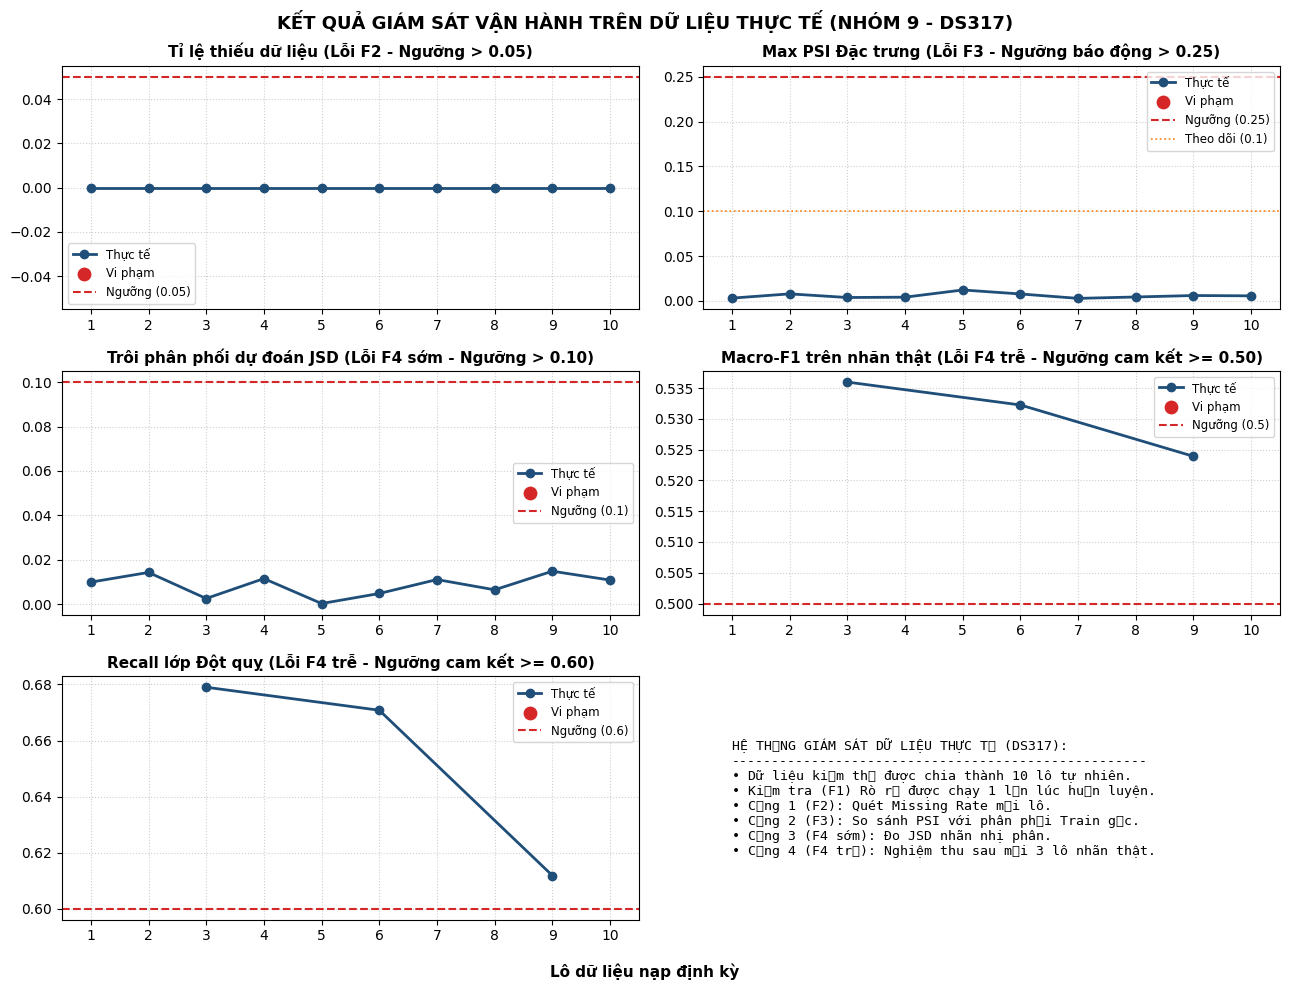

✓ Đã lưu bảng nhật ký vào 'monitoring_log.csv' và biểu đồ vào 'monitoring_dashboard.png'.


In [5]:
# ==============================================================================
# 5. TRỰC QUAN HÓA DASHBOARD GIÁM SÁT THỰC TẾ
# ==============================================================================
panels = [
    ("missing_rate", "Tỉ lệ thiếu dữ liệu (Lỗi F2 - Ngưỡng > 0.05)", MISSING_MAX, "above"),
    ("max_psi", "Max PSI Đặc trưng (Lỗi F3 - Ngưỡng báo động > 0.25)", PSI_ALERT, "above"),
    ("jsd", "Trôi phân phối dự đoán JSD (Lỗi F4 sớm - Ngưỡng > 0.10)", JSD_MAX, "above"),
    ("macro_f1", "Macro-F1 trên nhãn thật (Lỗi F4 trễ - Ngưỡng cam kết >= 0.50)", F1_MIN, "below"),
    ("recall", "Recall lớp Đột quỵ (Lỗi F4 trễ - Ngưỡng cam kết >= 0.60)", RECALL_MIN, "below"),
]

fig, axes = plt.subplots(3, 2, figsize=(13, 10))
axes = axes.ravel()

for ax, (col, title, thr, side) in zip(axes, panels):
    s = log_df.set_index("lo_du_lieu")[col].dropna()
    violated = (s > thr) if side == "above" else (s < thr)

    ax.plot(s.index, s.values, marker="o", color="#1f4e79", linewidth=2.0, label="Thực tế")
    ax.scatter(s.index[violated], s.values[violated], color="#d62728", s=80, zorder=3, label="Vi phạm")
    ax.axhline(thr, color="#d62728", linestyle="--", linewidth=1.5, label=f"Ngưỡng ({thr})")
    if col == "max_psi":
        ax.axhline(PSI_WATCH, color="#ff7f0e", linestyle=":", linewidth=1.2, label=f"Theo dõi ({PSI_WATCH})")

    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xticks(range(1, N_BATCHES + 1))
    ax.set_xlim(0.5, N_BATCHES + 0.5)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="best", fontsize=8.5)

axes[-1].axis("off")
axes[-1].text(
    0.05, 0.50,
    "HỆ THỐNG GIÁM SÁT DỮ LIỆU THỰC TẾ (DS317):\n"
    "----------------------------------------------------\n"
    "• Dữ liệu kiểm thử được chia thành 10 lô tự nhiên.\n"
    "• Kiểm tra (F1) Rò rỉ được chạy 1 lần lúc huấn luyện.\n"
    "• Cổng 1 (F2): Quét Missing Rate mỗi lô.\n"
    "• Cổng 2 (F3): So sánh PSI với phân phối Train gốc.\n"
    "• Cổng 3 (F4 sớm): Đo JSD nhãn nhị phân.\n"
    "• Cổng 4 (F4 trễ): Nghiệm thu sau mỗi 3 lô nhãn thật.",
    fontsize=9.5, verticalalignment="center", family="monospace"
)

fig.supxlabel("Lô dữ liệu nạp định kỳ", fontsize=11, fontweight="bold")
fig.suptitle("KẾT QUẢ GIÁM SÁT VẬN HÀNH TRÊN DỮ LIỆU THỰC TẾ (NHÓM 9 - DS317)", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig("monitoring_dashboard.png", dpi=200)
plt.show()

print("✓ Đã lưu bảng nhật ký vào 'monitoring_log.csv' và biểu đồ vào 'monitoring_dashboard.png'.")


### Đánh giá vận hành & Cơ chế phản ứng sự cố
1. **Tính khách quan:** Khi chạy trên các lô tự nhiên của dữ liệu kiểm thử thực tế, mô hình giữ vững các cam kết kỹ thuật nếu dữ liệu nạp vào đạt chuẩn.
2. **Cơ chế ngắt an toàn:** Bất cứ khi nào dữ liệu đầu vào phát sinh lỗi khuyết thiếu hoặc biến dạng schema, Cổng 1 lập tức kích hoạt ngắt mạch, bảo vệ bác sĩ và người dùng khỏi các phán đoán sai lầm.
3. **Cơ chế Champion - Challenger:** Nếu Cổng 4 phát hiện hiệu năng giảm sút dưới ngưỡng cam kết, hệ thống tự động kích hoạt tiến trình huấn luyện mô hình Challenger từ dữ liệu tích lũy mới và chỉ đưa vào phục vụ khi đã vượt qua mô hình Champion hiện hành trên cùng tập kiểm định.